<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QLSTM_WindowsMalware_Rani2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QLSTM for Windows malware detection: Rani and Mouleeswaran (2024) step by step

**Paper.** S. S. Rani, S. K. Mouleeswaran, *Windows Malware Detection Using Quantum Long Short Term Memory*, International Journal of Intelligent Engineering and Systems (IJIES), Vol. 17, No. 5, 2024, pp. 979-990. DOI: [10.22266/ijies2024.1031.73](https://doi.org/10.22266/ijies2024.1031.73).

**What this notebook does.** A Windows program is an *executable file* (a "PE file", Portable Executable). Without running it, we can read its header and obtain 77 numbers (number of sections, entropy of the sections, size of the image, ...). The paper (1) keeps only the numbers that a **LASSO regression** finds useful ("LRFS"), (2) cuts them into a short sequence and (3) feeds the sequence to a **Quantum LSTM (QLSTM)**: a normal LSTM network in which the small neural networks that form the gates are replaced by **variational quantum circuits**. The notebook rebuilds all of this on a quantum-circuit simulator, explains every step in plain language, trains classical ANN / RNN / LSTM / Random Forest / SVC / LightGBM models on exactly the same inputs, re-draws the paper's tables, and finishes with an honest claim-by-claim comparison with the paper.

**How to run.** Open in Google Colab (the badge above), choose a *CPU* runtime and use *Runtime -> Run all*. With `FAST_MODE = True` (the default shipped in the configuration cell) it needs about 10 minutes; the larger run is described in the configuration cell. If Colab asks for a session restart after the install cell, accept it and run again from the next cell.

**What you get at the end.** Plots of the real data, the drawn quantum circuit, loss curves, the paper's Tables 2-7 re-computed, and a verdict ("reproduced", "not reached", "exceeded", "cannot be checked") for each claim.

## The paper in one page

* **Problem.** Windows is the main target of malware. Static analysis (reading the file header without running the program) is cheap, but the header has many redundant numbers.
* **Decision.** Binary, per file: malicious (1) or benign (0).
* **Method (Fig. 1).** Windows PE dataset -> 70/30 train/test split -> **LRFS** (L1-regularised LASSO regression keeps the features with non-zero coefficients) -> the selected features are arranged as a sequence -> **QLSTM** -> accuracy, precision, sensitivity, recall, F1.
* **QLSTM (Section 3.3, Eqs. 5-11, Figs. 2-4).** Six variational quantum circuits (VQC1 ... VQC6) replace the neural networks of the LSTM: VQC1 = forget gate, VQC2 = input gate, VQC3 = cell candidate, VQC4 = output gate, VQC5 produces the hidden state `h_t = sigmoid(VQC5(o_t * tanh(c_t)))`, VQC6 produces the output `y_t = VQC6(o_t * tanh(c_t))`. Every VQC takes `v_t = [h_(t-1), x_t]`, is initialised with a Hadamard feature map and then has trainable layers.
* **Hyper-parameters (Table 1).** 8 layers, learning rate 0.01, 100 epochs, Adam. (Chosen by random search, not shown.)
* **Data.** "Windows PE malware detection dataset" from Kaggle (Ref. 25): 77 header features, label 1 = malicious, 0 = benign. The paper says 19,611 malware and 31,600 benign samples (38.54% / 61.46%).
* **Claims checked here.** Table 2 (ANN, RNN, LSTM, QLSTM without feature selection), Table 3 (the same with LRFS), Table 4 (LRFS against Chi-square, RFE and linear-regression selection), Table 5 (2, 4, 6, 8 layers), Table 6 (2 to 5 cross folds), Table 7 (comparison with other published detectors) and the headline: accuracy 98.85% (70/30 split) and F1 99.36% (best fold).

## What follows the paper and what had to be chosen

The paper gives no code, no circuit diagram in text form (Figs. 2-4 are images), no number of qubits, no sequence layout, no batch size, no hidden size and no LASSO penalty. Everything not given is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | Kaggle "Windows PE malware detection dataset"; text says 19,611 malware + 31,600 benign | The public Hugging Face mirror of the Kaggle PE dataset `amauricio/pe-files-malwares`: **19,611 files in total** (14,599 malware from VirusShare + 5,012 benign), 77 header features. The count 19,611 and the 77 features agree with the paper; the class counts in the paper's text do **not** (see "Reading the paper critically"). The login-only Kaggle original (`nsaravana/malware-detection`) could not be downloaded here. |
| Split | 70 % train / 30 % test | 70/30 stratified, `random_state = SEED`; exact duplicate rows are removed first (a duplicate in both parts would leak) |
| Pre-processing | not described | signed log, standardisation and clipping, **fitted on the training rows only**; the identifier `Name` is dropped (it contains the word "VirusShare" for malware, i.e. the label) |
| Feature selection | LASSO, penalty not given | LASSO on the 0/1 label; penalty chosen by 3-fold cross-validation with the one-standard-error rule, on the training rows only |
| Sequence | "sequences of selected features" | the selected features, in the original column order, are cut into steps of `G_STEP = 8` features (zero-padded); one QLSTM step reads one group of 8 |
| Qubits / encoding | not given; Hadamard feature map, then variational layers | 4 qubits; H, then RY(arctan x) and RZ(arctan x^2) data encoding (as in Chen et al.'s QLSTM), then 8 layers of CNOT ladder + `Rot` rotations |
| Six VQCs | VQC1-4 gates, VQC5 hidden state, VQC6 output | all six implemented; VQC6 is evaluated at the last step only (its output is only used there) |
| Optimiser | Adam, lr 0.01, 100 epochs, 8 layers | Adam, lr 0.01, 8 layers; epochs and training-set size limited by the CPU simulator (budgets in the configuration cell) |
| Classical baselines | ANN, RNN, LSTM (Table 2/3) | the same three, with the **same inputs, hidden size, optimiser, batch and epochs** as the QLSTM, plus Random Forest, SVC (RBF) and LightGBM |
| Other detectors (Table 7) | PROUD-MAL, DL-CNN, M-Attn, LGBM numbers copied from their own papers | cannot be re-run on this data; only LightGBM is re-run |

## 0. Setup

Colab already ships NumPy, pandas, scikit-learn, matplotlib, PyTorch and LightGBM. We add PennyLane, the framework used for the quantum circuit, and `huggingface_hub` for the data download. The cell does nothing when everything is already installed (for example on a local machine). If Colab asks you to restart the session, accept and run again from the next cell.

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and lightgbm. We add PennyLane (pinned to the tested version).
# The cell does nothing when PennyLane is already available (for example on a local machine).
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
need = [m for m in ("pennylane", "huggingface_hub", "lightgbm", "torch") if importlib.util.find_spec(m) is None]
if IN_COLAB or need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "requests", "lightgbm"], check=True)
    print("Installed pennylane==0.45.1 (and missing helpers). If Colab asks you to restart the session, accept and run again from the next cell.")
else:
    print("PennyLane, PyTorch, LightGBM and huggingface_hub already available, nothing to install.")

PennyLane, PyTorch, LightGBM and huggingface_hub already available, nothing to install.


The **configuration cell** holds every tunable constant. `FAST_MODE = True` shrinks the training sets, the number of epochs and the number of seeds so that the notebook runs in about 10 minutes; `FAST_MODE = False` is the larger run (budgets in the cell). No quantum-hardware token is needed because the paper used a simulator (`IBM_TOKEN` is kept for the project convention and is not used).

In [2]:
# ------------------------------- configuration: every tunable constant lives here -------------------------------
SEED = 42
FAST_MODE = False      # True: about 10 minute class demo. False: larger training sets, more epochs and seeds (budgets below).
DATA_DIR = "malware_pe_data"     # cache folder for the downloaded CSV
LOCAL_CSV = ""                   # optional: path of an uploaded copy of dataset_malwares.csv
IBM_TOKEN = ""                   # not used: the paper ran a simulator only (kept for the convention)

HF_REPO = "jason1966/amauricio_pe-files-malwares"      # public Hugging Face mirror of the Kaggle PE dataset
HF_FILE = "dataset_malwares.csv"

# --- constants from the paper ---
TEST_SIZE = 0.30       # paper: 70 % training / 30 % testing
Q_DEPTH = 8            # paper Table 1: 8 layers
Q_LR = 0.01            # paper Table 1: learning rate 0.01 (optimiser Adam)
PAPER_EPOCHS = 100     # paper Table 1: 100 epochs (not affordable on a CPU simulator for every model, see EPOCHS)

# --- choices the paper leaves open (marked # CHOICE: where they are used) ---
N_QUBITS = 4           # CHOICE: number of qubits per VQC (the paper does not state it)
G_STEP = 8             # CHOICE: features read per LSTM time step (one group of G_STEP selected features)
Q_HIDDEN = 8           # CHOICE: hidden size of the QLSTM and of the matched classical RNN / LSTM
Q_BATCH = 64           # CHOICE: mini-batch size (not given)
DEDUP = True           # CHOICE: drop exact duplicate rows before splitting (no duplicate may sit in both train and test)
TRACK_N = 1000         # CHOICE: the per-epoch test-loss curves use the first 1000 test files (the final metrics use all test files)
SVC_MAX = 4000         # CHOICE: the RBF SVC is trained on at most this many rows (kernel SVC cost grows quadratically)

if FAST_MODE:
    N_TRAIN, EPOCHS, N_SEEDS, N_SEEDS_SWEEP, RF_TREES = 640, 8, 1, 1, 100
else:
    # paper: all training rows x 100 epochs. Here: a subsample of the training rows and fewer epochs (CPU state-vector simulation).
    N_TRAIN, EPOCHS, N_SEEDS, N_SEEDS_SWEEP, RF_TREES = 1600, 30, 3, 2, 300

In [3]:
import os, io, time, math, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn, lightgbm
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LassoCV, Lasso, LogisticRegression, LinearRegression
from sklearn.feature_selection import SelectKBest, chi2, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")

# Hugging Face token: only needed for gated datasets (this mirror is public). Never printed, never written to a file.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def set_seed(s):
    s = int(s); np.random.seed(s % (2**32 - 1)); torch.manual_seed(s)

set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| lightgbm", lightgbm.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN =", N_TRAIN, "| epochs =", EPOCHS, "(paper: %d)" % PAPER_EPOCHS, "| seeds =", N_SEEDS)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | lightgbm 4.7.0
FAST_MODE = False | N_TRAIN = 1600 | epochs = 30 (paper: 100) | seeds = 3


## 1. Data: 77 header numbers of Windows executables

Each row is one Windows executable (PE file). The 77 columns are numbers read from its header: sizes (`SizeOfCode`, `SizeOfImage`), versions (`MajorLinkerVersion`), the number of sections, the minimum and maximum *entropy* of the sections (packed or encrypted code has high entropy), counts of suspicious imports, ... The label `Malware` is 1 for a malicious file (collected from the VirusShare repository) and 0 for a benign one. The column `Name` identifies the file; it is **not** a feature (for malware it starts with "VirusShare_", which would give the label away).

The code downloads the CSV once into `DATA_DIR` (6.7 MB) and checks its size against what we found when we inspected it: 19,611 rows, 14,599 malware and 5,012 benign.

In [4]:
def fetch_csv():
    if LOCAL_CSV and os.path.exists(LOCAL_CSV): return LOCAL_CSV
    dest = os.path.join(DATA_DIR, HF_FILE)
    if os.path.exists(dest) and os.path.getsize(dest) > 1_000_000: return dest
    try:
        from huggingface_hub import hf_hub_download
        return hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    except Exception as e:
        print("huggingface_hub download failed:", repr(e)[:150], "-> trying the direct URL")
    url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{HF_FILE}"
    headers = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    with requests.get(url, headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
    return dest

csv_path = fetch_csv()
raw = pd.read_csv(csv_path)
raw.columns = raw.columns.str.strip()
print("raw shape (rows, columns):", raw.shape)
print(raw["Malware"].value_counts().rename({1: "malware (1)", 0: "benign (0)"}).to_string())
assert raw.shape == (19_611, 79), "unexpected shape"
assert (raw["Malware"] == 1).sum() == 14_599 and (raw["Malware"] == 0).sum() == 5_012, "unexpected class counts"
src_prefix = raw["Name"].astype(str).str.split("_").str[0]
print("\nfirst token of the file name, by class (shows why `Name` must not be a feature):")
print(pd.crosstab(src_prefix.where(src_prefix == "VirusShare", "other (benign system/app files)"), raw["Malware"]).to_string())

raw shape (rows, columns): (19611, 79)
Malware
malware (1)    14599
benign (0)      5012

first token of the file name, by class (shows why `Name` must not be a feature):
Malware                             0      1
Name                                        
VirusShare                          0  14599
other (benign system/app files)  5012      0


## 2. Cleaning, split and pre-processing (training rows only)

In this order, so that **nothing from the test part influences training**:

1. Drop `Name`; **remove exact duplicate rows** (identical 77 numbers and label). The Kaggle file contains thousands of them, and a duplicate that lands in both the training and the test part would be a free correct answer.
2. Stratified **70 % / 30 %** split (the paper's ratio).
3. Fitted on the training rows only: remove constant columns; signed log `sign(x) * log(1 + |x|)` (header values range from 0 to 10^13); standardisation; clipping to +-5.

In [5]:
y_all_raw = raw["Malware"].to_numpy().astype(int)
X_df = raw.drop(columns=["Name", "Malware"]).apply(pd.to_numeric, errors="coerce")
FEATURES_RAW = list(X_df.columns)
assert len(FEATURES_RAW) == 77 and not X_df.isna().any().any()
dup = pd.concat([X_df, pd.Series(y_all_raw, name="y")], axis=1).duplicated().to_numpy()
print(f"exact duplicate rows (features + label): {dup.sum():,} of {len(dup):,}")
keep_rows = ~dup if DEDUP else np.ones(len(dup), bool)
X_all, y_all = X_df.to_numpy(np.float64)[keep_rows], y_all_raw[keep_rows]
print("rows used:", len(y_all), "| malware share %.3f" % y_all.mean())

Xtr_raw, Xte_raw, ytr, yte = train_test_split(X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)   # paper: 70/30
print("train", Xtr_raw.shape, "test", Xte_raw.shape, "| malware share train %.3f test %.3f" % (ytr.mean(), yte.mean()))

slog = lambda a: np.sign(a) * np.log1p(np.abs(a))
const = Xtr_raw.std(0) == 0                                  # constant on the training rows
print("constant columns removed:", [f for f, c in zip(FEATURES_RAW, const) if c])
FEATURES = [f for f, c in zip(FEATURES_RAW, const) if not c]
F_IN = len(FEATURES)
scaler = StandardScaler().fit(slog(Xtr_raw[:, ~const]))
prep = lambda a: np.clip(scaler.transform(slog(a[:, ~const])), -5, 5).astype(np.float32)
Ztr, Zte = prep(Xtr_raw), prep(Xte_raw)
print("model features:", F_IN, "| Ztr", Ztr.shape, "Zte", Zte.shape)

exact duplicate rows (features + label): 2,980 of 19,611
rows used: 16631 | malware share 0.701
train (11641, 77) test (4990, 77) | malware share train 0.701 test 0.701
constant columns removed: ['e_magic', 'SectionMaxEntropy', 'SectionMaxRawsize', 'SectionMaxVirtualsize', 'SectionMinPhysical', 'SectionMinVirtual', 'SectionMinPointerData', 'SectionMainChar']


model features: 69 | Ztr (11641, 69) Zte (4990, 69)


## 3. Feature selection: LASSO (LRFS) and the three rivals of Table 4

**LASSO.** Linear regression `label ~ intercept + sum_j coefficient_j * feature_j`, with an added penalty `lambda * sum |coefficient_j|` (the L1 norm, Eq. 2). The penalty pushes the coefficients of useless features to exactly zero; the features with a non-zero coefficient are the selected subset. The paper does not give `lambda`: we choose it on the training rows only, by 3-fold cross-validation with the *one-standard-error rule* (the strongest penalty whose cross-validated error is within one standard error of the best), because the plain best-error penalty keeps almost every feature.

**Rivals (Table 4).** Chi-square (`SelectKBest`), RFE (recursive elimination with logistic regression) and "LR" (the `k` features with the largest ordinary linear-regression coefficients). They all keep the same number `k` of features as LRFS, so that only *which* features differ.

LASSO penalty (1-SE rule) = 0.00147 (best-error penalty would be 0.00029) -> 47 of 69 features kept [6s]
kept: ['e_cp', 'e_minalloc', 'e_maxalloc', 'e_sp', 'e_ip', 'e_lfarlc', 'e_ovno', 'e_lfanew', 'NumberOfSections', 'TimeDateStamp', 'SizeOfOptionalHeader', 'Characteristics', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'ImageBase', 'SectionAlignment', 'FileAlignment', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion', 'SizeOfHeaders', 'CheckSum', 'Subsystem', 'DllCharacteristics', 'SizeOfStackReserve', 'SizeOfStackCommit', 'SuspiciousImportFunctions', 'SectionMinEntropy', 'SectionMinVirtualsize', 'SectionMaxPhysical', 'SectionMaxPointerData', 'SectionMaxChar', 'DirectoryEntryImport', 'DirectoryEntryImportSize', 'DirectoryEntryExport', 'ImageDirectoryEntryExport', 'ImageDirectoryEntr


number of features shared between the selections:
            Chi-Square  RFE  LR  LRFS
Chi-Square          47   34  34    33
RFE                 34   47  33    34
LR                  34   33  47    37
LRFS                33   34  37    47


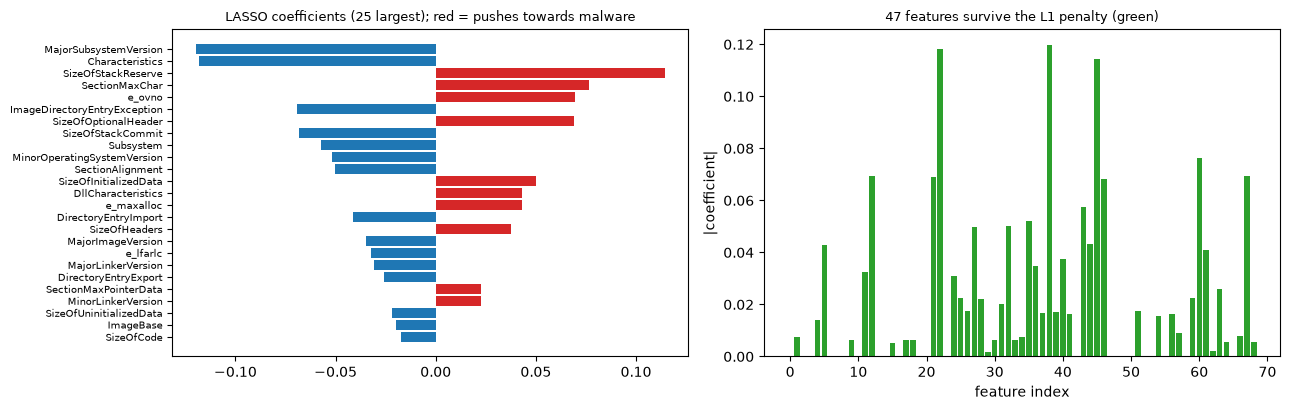

In [6]:
def lasso_1se(Z, y):
    alphas = np.logspace(-4, -0.5, 16)
    cv = LassoCV(alphas=alphas, cv=3, random_state=SEED, max_iter=2000).fit(Z, y)
    mse = cv.mse_path_.mean(1); se = cv.mse_path_.std(1) / np.sqrt(cv.mse_path_.shape[1])
    best = int(np.argmin(mse)); ok = np.flatnonzero(mse <= mse[best] + se[best])
    a = float(cv.alphas_[ok[np.argmax(cv.alphas_[ok])]])         # CHOICE: one-standard-error rule
    return Lasso(alpha=a, max_iter=5000).fit(Z, y), a, float(cv.alpha_)

t0 = time.time()
lasso, A_LASSO, A_BEST = lasso_1se(Ztr, ytr)
LRFS_COLS = np.flatnonzero(lasso.coef_ != 0)
K = len(LRFS_COLS)
print(f"LASSO penalty (1-SE rule) = {A_LASSO:.5f} (best-error penalty would be {A_BEST:.5f}) -> {K} of {F_IN} features kept [{time.time()-t0:.0f}s]")
print("kept:", [FEATURES[j] for j in LRFS_COLS])

# --- the three rivals, each keeping the same number K of features, fitted on the training rows only ---
mm01 = MinMaxScaler((0, 1)).fit(Ztr)
chi_cols = np.sort(SelectKBest(chi2, k=K).fit(mm01.transform(Ztr), ytr).get_support(indices=True))
sub_rfe = np.random.default_rng(SEED).choice(len(Ztr), size=min(6000, len(Ztr)), replace=False)       # CHOICE: RFE fitted on at most 6000 rows (speed)
rfe_cols = np.sort(np.flatnonzero(RFE(LogisticRegression(max_iter=300), n_features_to_select=K, step=0.15).fit(Ztr[sub_rfe], ytr[sub_rfe]).support_))
ols = LinearRegression().fit(Ztr, ytr)
lr_cols = np.sort(np.argsort(-np.abs(ols.coef_))[:K])
FS_COLS = {"Chi-Square": chi_cols, "RFE": rfe_cols, "LR": lr_cols, "LRFS": LRFS_COLS}
ALL_COLS = np.arange(F_IN)
ov = pd.DataFrame({a: [len(set(FS_COLS[a]) & set(FS_COLS[b])) for b in FS_COLS] for a in FS_COLS}, index=list(FS_COLS))
print("\nnumber of features shared between the selections:"); print(ov.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
order = np.argsort(-np.abs(lasso.coef_))[:25]
ax[0].barh([FEATURES[j] for j in order][::-1], lasso.coef_[order][::-1], color=["tab:red" if lasso.coef_[j] > 0 else "tab:blue" for j in order][::-1])
ax[0].set_title("LASSO coefficients (25 largest); red = pushes towards malware", fontsize=9); ax[0].tick_params(axis="y", labelsize=7)
ax[1].bar(range(F_IN), np.abs(lasso.coef_), color=["tab:green" if j in set(LRFS_COLS) else "lightgray" for j in range(F_IN)])
ax[1].set_xlabel("feature index"); ax[1].set_ylabel("|coefficient|"); ax[1].set_title(f"{K} features survive the L1 penalty (green)", fontsize=9)
plt.tight_layout(); plt.show()

Now the **sequences**. The paper feeds "sequences of the selected features" to the QLSTM without saying how. Our choice: take the selected features in their original column order and cut them into groups of `G_STEP = 8`; the LSTM reads one group per time step (zero-padded at the end). Without feature selection the same rule gives one longer sequence of all non-constant features. Note that PE-header fields have no natural time order: the "sequence" is an arrangement, not a recording (see the critical reading).

In [7]:
def to_seq(Z, cols, g=G_STEP):
    sub = Z[:, cols]; T = int(math.ceil(sub.shape[1] / g)); pad = np.zeros((len(sub), T * g - sub.shape[1]), np.float32)
    return np.concatenate([sub, pad], 1).reshape(len(sub), T, g)          # (samples, time steps, features per step)

SEQ = {}
for nm, cols in {"no feature selection": ALL_COLS, **FS_COLS}.items():
    SEQ[nm] = (to_seq(Ztr, cols), to_seq(Zte, cols))
    print(f"{nm:22s} {len(cols):3d} features -> sequences {SEQ[nm][0].shape[1:]}  (train {SEQ[nm][0].shape}, test {SEQ[nm][1].shape})")

no feature selection    69 features -> sequences (9, 8)  (train (11641, 9, 8), test (4990, 9, 8))
Chi-Square              47 features -> sequences (6, 8)  (train (11641, 6, 8), test (4990, 6, 8))
RFE                     47 features -> sequences (6, 8)  (train (11641, 6, 8), test (4990, 6, 8))
LR                      47 features -> sequences (6, 8)  (train (11641, 6, 8), test (4990, 6, 8))
LRFS                    47 features -> sequences (6, 8)  (train (11641, 6, 8), test (4990, 6, 8))


## Dataset Exploration and Visualisation

The data the models actually see: original labels and class counts, the class distribution, and 2-D projections of **real executables coloured by their ground-truth label** (`Malware`: 1 = malicious from VirusShare, 0 = benign). The dataset has two original label values only (no malware family column), so there is no multiclass colouring. Every PCA is fitted on the training split. First the raw PCA coordinates, then the same coordinates scaled to [0, pi] (the angle range of a quantum rotation gate), then the PCA of the exact inputs of the QLSTM (the LRFS-selected sequences).

raw dataset shape (rows, columns incl. Name and label): (19611, 79)
rows after removing duplicates: 16631 | train 11641 | test 4990
original label values and counts (raw file):
malware (1)    14599
benign (0)      5012

all 77 numeric features:
['e_magic', 'e_cblp', 'e_cp', 'e_crlc', 'e_cparhdr', 'e_minalloc', 'e_maxalloc', 'e_ss', 'e_sp', 'e_csum', 'e_ip', 'e_cs', 'e_lfarlc', 'e_ovno', 'e_oemid', 'e_oeminfo', 'e_lfanew', 'Machine', 'NumberOfSections', 'TimeDateStamp', 'PointerToSymbolTable', 'NumberOfSymbols', 'SizeOfOptionalHeader', 'Characteristics', 'Magic', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'ImageBase', 'SectionAlignment', 'FileAlignment', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion', 'SizeOfHeaders', 'CheckSum', 'SizeOfImage', 'Subsystem', 'DllCharacteristics', '

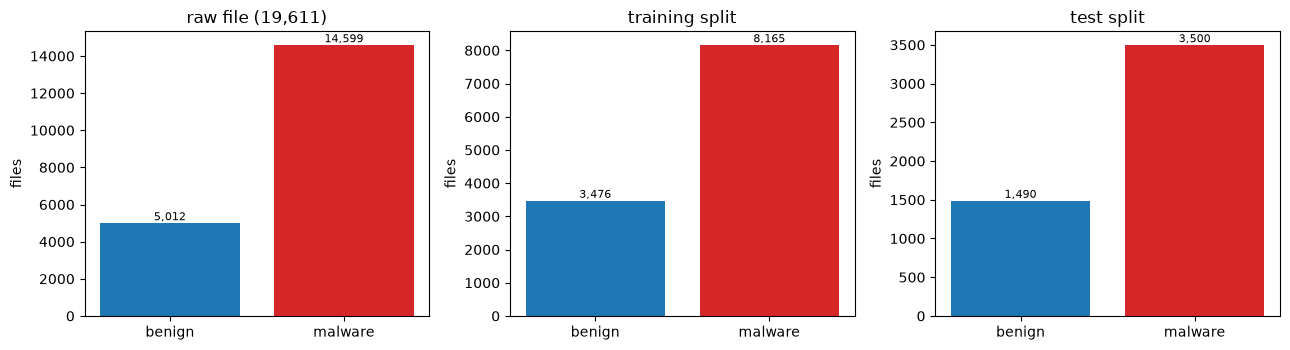

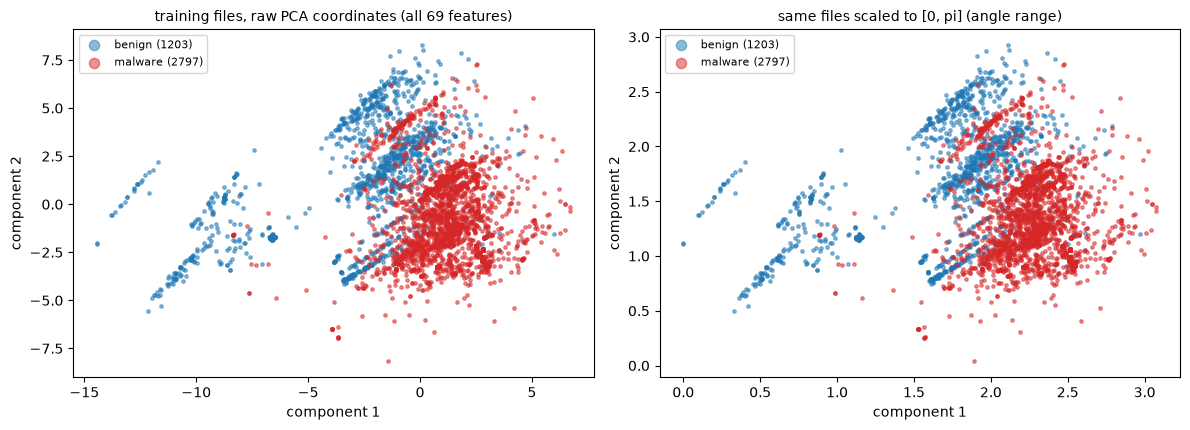

PCA explained variance of the two components (training split): 0.167, 0.134


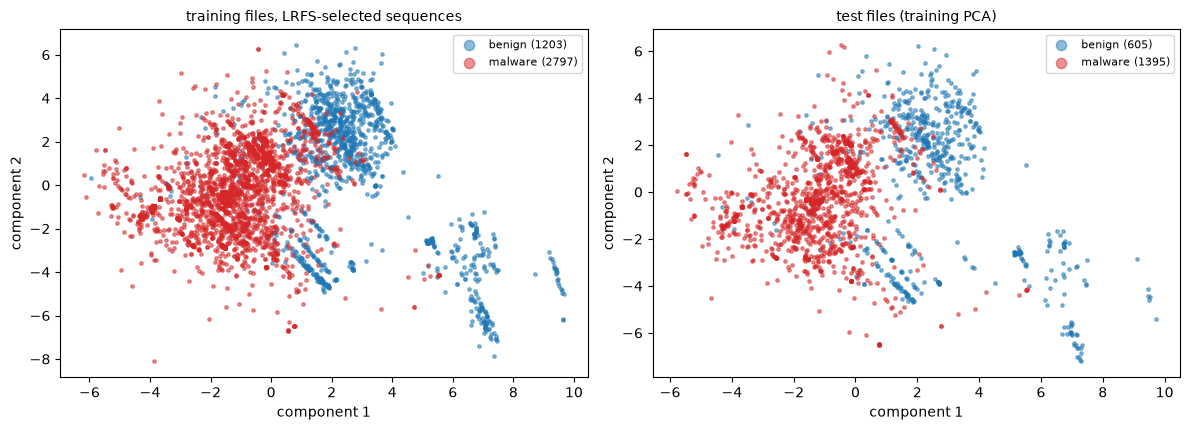

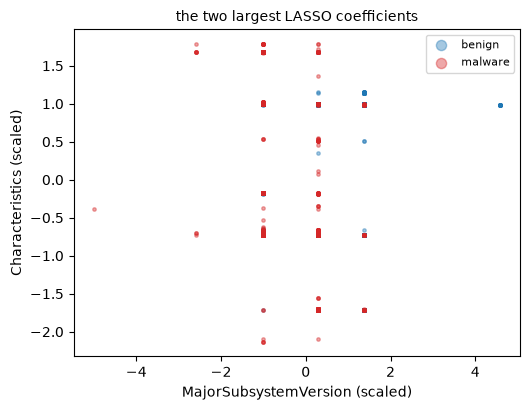

In [8]:
print("raw dataset shape (rows, columns incl. Name and label):", raw.shape)
print("rows after removing duplicates:", len(y_all), "| train", len(ytr), "| test", len(yte))
print("original label values and counts (raw file):"); print(pd.Series(np.where(y_all_raw == 1, "malware (1)", "benign (0)")).value_counts().to_string())
print("\nall %d numeric features:" % len(FEATURES_RAW)); print(FEATURES_RAW)
print("\n%d features after removing constant columns; %d kept by LRFS:" % (F_IN, K)); print([FEATURES[j] for j in LRFS_COLS])

col = {0: "tab:blue", 1: "tab:red"}; lab = {0: "benign", 1: "malware"}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (nm, yy) in zip(ax, (("raw file (19,611)", y_all_raw), ("training split", ytr), ("test split", yte))):
    cnt = [(yy == 0).sum(), (yy == 1).sum()]; b = a.bar(["benign", "malware"], cnt, color=[col[0], col[1]]); a.set_title(nm); a.set_ylabel("files")
    for r, c_ in zip(b, cnt): a.text(r.get_x() + r.get_width() / 2, c_, f"{c_:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

# ---- 2-D projection of real files: raw PCA coordinates (fitted on the training split), coloured by the true label ----
sub = np.random.default_rng(SEED).choice(len(Ztr), size=min(4000, len(Ztr)), replace=False)
pca2 = PCA(n_components=2, random_state=SEED).fit(Ztr)
P_tr = pca2.transform(Ztr[sub]); mm = MinMaxScaler((0, np.pi)).fit(pca2.transform(Ztr)); A_tr = np.clip(mm.transform(P_tr), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (Pt, ttl) in enumerate(((P_tr, "training files, raw PCA coordinates (all %d features)" % F_IN), (A_tr, "same files scaled to [0, pi] (angle range)"))):
    for c_ in (0, 1):
        m_ = ytr[sub] == c_; ax[k].scatter(Pt[m_, 0], Pt[m_, 1], s=6, alpha=.5, c=col[c_], label=f"{lab[c_]} ({m_.sum()})")
    ax[k].set_title(ttl, fontsize=10); ax[k].set_xlabel("component 1"); ax[k].set_ylabel("component 2"); ax[k].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()
print("PCA explained variance of the two components (training split): %.3f, %.3f" % tuple(pca2.explained_variance_ratio_))

# ---- the exact QLSTM input: LRFS-selected sequences flattened, training PCA, train and test files ----
S_tr, S_te = SEQ["LRFS"]
pca_s = PCA(n_components=2, random_state=SEED).fit(S_tr.reshape(len(S_tr), -1))
sub_te = np.random.default_rng(SEED + 1).choice(len(S_te), size=min(2000, len(S_te)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (Sx, yy, ttl) in enumerate(((S_tr[sub], ytr[sub], "training files, LRFS-selected sequences"), (S_te[sub_te], yte[sub_te], "test files (training PCA)"))):
    Pt = pca_s.transform(Sx.reshape(len(Sx), -1))
    for c_ in (0, 1):
        m_ = yy == c_; ax[k].scatter(Pt[m_, 0], Pt[m_, 1], s=6, alpha=.5, c=col[c_], label=f"{lab[c_]} ({m_.sum()})")
    ax[k].set_title(ttl, fontsize=10); ax[k].set_xlabel("component 1"); ax[k].set_ylabel("component 2"); ax[k].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

# ---- two of the most informative real features, by class ----
top2 = [FEATURES[j] for j in np.argsort(-np.abs(lasso.coef_))[:2]]
fig, ax = plt.subplots(figsize=(5.4, 4.2))
for c_ in (0, 1):
    m_ = ytr[sub] == c_; ax.scatter(Ztr[sub][m_, FEATURES.index(top2[0])], Ztr[sub][m_, FEATURES.index(top2[1])], s=6, alpha=.4, c=col[c_], label=lab[c_])
ax.set_xlabel(top2[0] + " (scaled)"); ax.set_ylabel(top2[1] + " (scaled)"); ax.set_title("the two largest LASSO coefficients", fontsize=10); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The QLSTM contains **six variational quantum circuits** (VQC1-VQC6) of the *same architecture* with their own trainable angles; VQC1-VQC4 are the forget, input, candidate and output gates and VQC5 / VQC6 produce the hidden state and the output (paper Eqs. 5-11). The drawing is made from the real PennyLane QNode (`default.qubit`) that the notebook uses as reference simulator. Its pieces, in the order they act:

1. **Hadamard on every qubit** (paper Eq. 3, "Hadamard feature map"): the equal superposition.
2. **Data encoding**: qubit *i* receives one classical number *x_i* through `RY(arctan x_i)` then `RZ(arctan x_i^2)`. *Assumption (paper silent):* the encoding of Chen, Yoo and Fang's QLSTM, on which the paper's QLSTM is modelled.
3. **Variational layers** (`Q_DEPTH = 8`, the "number of layers" of Table 1): each layer is a **CNOT ladder** (entanglement: pairs (0,1), (2,3), ... then (1,2), (3,4), ...) followed by a trainable **`Rot(phi, theta, omega)`** on every qubit.
4. **Measurement**: the expectation value of Pauli-Z on every qubit, one number per qubit, which the classical layers around the circuit turn into the gate value.

*Assumptions (paper silent):* number of qubits (4), the exact gate sequence of Figs. 2-3, the entangler, how many classical numbers enter a circuit (a linear layer squeezes `[h, x]` to 4 angles, as in Chen et al.).

Matplotlib is building the font cache; this may take a moment.


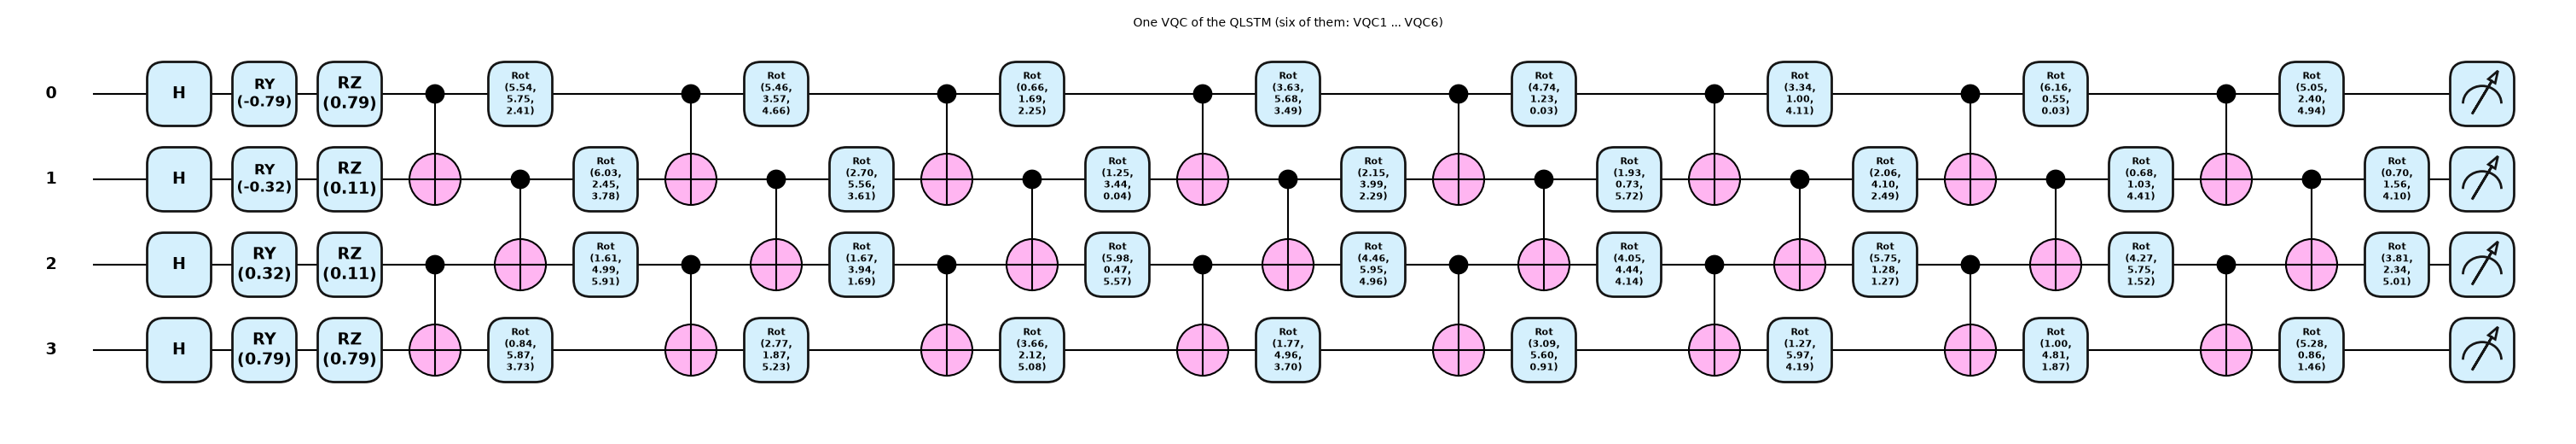

qubits: 4 | circuit depth: 27 | gates: 68 | gate types: {'Hadamard': 4, 'RY': 4, 'RZ': 4, 'CNOT': 24, 'Rot': 32}
trainable parameters per VQC: 8 layers x 4 qubits x 3 angles = 96
trainable circuit parameters in the whole QLSTM cell (6 VQCs): 576


In [9]:
def make_pl_vqc(n=N_QUBITS, L=Q_DEPTH):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def vqc(inputs, weights):
        for i in range(n): qml.Hadamard(wires=i)                                            # paper Eq. 3: Hadamard feature map
        for i in range(n): qml.RY(torch.arctan(inputs[..., i]), wires=i)                    # CHOICE: Chen et al. QLSTM encoding
        for i in range(n): qml.RZ(torch.arctan(inputs[..., i] ** 2), wires=i)
        for l in range(L):                                                                  # paper Table 1: 8 layers
            for i in range(0, n - 1, 2): qml.CNOT(wires=[i, i + 1])                         # CHOICE: CNOT ladder + Rot layer
            for i in range(1, n - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(n): qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]                                # <Z_i>, one number per qubit
    return vqc

PL_VQC = make_pl_vqc()
x_demo = torch.linspace(-1.0, 1.0, N_QUBITS); w_demo = torch.rand(Q_DEPTH, N_QUBITS, 3) * 2 * math.pi
fig, ax = qml.draw_mpl(PL_VQC, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle("One VQC of the QLSTM (six of them: VQC1 ... VQC6)", fontsize=10); plt.show()

sp = qml.specs(PL_VQC)(x_demo, w_demo)
try:
    res = sp["resources"]; depth, n_gates, gate_types = res.depth, res.num_gates, dict(res.gate_types)
except Exception:
    depth, n_gates, gate_types = sp.get("depth"), sp.get("num_operations"), sp.get("gate_types")
print(f"qubits: {N_QUBITS} | circuit depth: {depth} | gates: {n_gates} | gate types: {gate_types}")
print(f"trainable parameters per VQC: {Q_DEPTH} layers x {N_QUBITS} qubits x 3 angles = {Q_DEPTH * N_QUBITS * 3}")
print(f"trainable circuit parameters in the whole QLSTM cell (6 VQCs): {6 * Q_DEPTH * N_QUBITS * 3}")

### A fast twin of the circuit, proved equal to PennyLane

Training needs one circuit evaluation per VQC, per time step and per batch, with gradients, thousands of times. PennyLane's `default.qubit` is correct but slow in this setting, so the training loop uses a **PyTorch twin**: the same circuit written as an exact state-vector computation (the encoding gives a product state; each layer is one 2^n x 2^n unitary built from the `Rot` angles; Pauli-Z expectations are read from the probabilities). The next cell proves that twin and QNode are the same function, for **values and gradients**, in float64, for several depths.

In [10]:
_tab = {}
def tables(n):
    if n not in _tab:
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1                      # wire 0 = most significant bit (PennyLane order)
        zsign = torch.tensor(1.0 - 2.0 * bits, dtype=torch.float64)
        pairs = [(i, i + 1) for i in range(0, n - 1, 2)] + [(i, i + 1) for i in range(1, n - 1, 2)]
        perm = idx.copy()
        for c_, t_ in pairs:
            fl = idx ^ (((idx >> (n - 1 - c_)) & 1) << (n - 1 - t_)); perm = perm[fl]       # the CNOT ladder as a basis permutation
        _tab[n] = (zsign, torch.tensor(perm, dtype=torch.long))
    return _tab[n]

def layer_unitaries(weights, cdt):
    # weights (G, L, n, 3) -> list of L unitaries (G, 2^n, 2^n): tensor product of Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) on every wire
    G, L, n, _ = weights.shape; Ws = []
    for l in range(L):
        phi, th, om = weights[:, l, :, 0], weights[:, l, :, 1], weights[:, l, :, 2]
        c_, s_ = torch.cos(th / 2).to(cdt), torch.sin(th / 2).to(cdt); a_, b_ = ((phi + om) / 2).to(cdt), ((phi - om) / 2).to(cdt)
        M = torch.stack([torch.stack([torch.exp(-1j * a_) * c_, -torch.exp(1j * b_) * s_], -1),
                         torch.stack([torch.exp(-1j * b_) * s_, torch.exp(1j * a_) * c_], -1)], -2)       # (G, n, 2, 2)
        W = M[:, 0]
        for k in range(1, n):
            d = W.shape[-1]; W = torch.einsum('gab,gcd->gacbd', W, M[:, k]).reshape(G, 2 * d, 2 * d)
        Ws.append(W)
    return Ws

def expect_twin(inputs, Ws, n):
    # inputs (G, B, n) -> (G, B, n): <Z_i> of G independent circuits on B inputs each (float32 or float64 follows the input dtype)
    G, B, _ = inputs.shape; dt = inputs.dtype; cdt = torch.complex64 if dt == torch.float32 else torch.complex128
    zsign, perm = tables(n); zsign = zsign.to(dt)
    a = torch.arctan(inputs) / 2; b = torch.arctan(inputs ** 2) / 2                       # half angles of RY(arctan x), RZ(arctan x^2)
    c_, s_ = torch.cos(a), torch.sin(a); r2 = 1 / math.sqrt(2)
    q = torch.stack([((c_ - s_) * r2).to(cdt) * torch.exp(-1j * b.to(cdt)), ((s_ + c_) * r2).to(cdt) * torch.exp(1j * b.to(cdt))], -1)   # RZ RY H|0> per wire
    psi = q[:, :, 0, :]
    for k in range(1, n): psi = (psi.unsqueeze(-1) * q[:, :, k, :].unsqueeze(-2)).reshape(G, B, -1)                                    # product state
    for W in Ws:
        psi = psi[..., perm]                                                              # CNOT ladder
        psi = torch.bmm(psi, W.transpose(1, 2))                                           # Rot layer
    return (psi.real ** 2 + psi.imag ** 2) @ zsign

def expect_pl(inputs, weights, vqc=None):
    # same quantity from the PennyLane QNode (reference); inputs (G, B, n) are broadcast over B
    vqc = vqc or PL_VQC
    return torch.stack([torch.stack(vqc(inputs[g], weights[g]), -1) for g in range(inputs.shape[0])])

# ---- proof: twin == PennyLane, values and gradients (float64), several depths ----
torch.manual_seed(SEED); G_, B_ = 3, 5
for L_ in (1, 2, 4, Q_DEPTH):
    vq = make_pl_vqc(N_QUBITS, L_)
    xs = (torch.randn(G_, B_, N_QUBITS, dtype=torch.float64) * 2).requires_grad_()
    ws = (torch.rand(G_, L_, N_QUBITS, 3, dtype=torch.float64) * 2 * math.pi).requires_grad_()
    ref = expect_pl(xs, ws, vq); tw = expect_twin(xs, layer_unitaries(ws, torch.complex128), N_QUBITS)
    gr = torch.autograd.grad((ref * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws)); gt = torch.autograd.grad((tw * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws))
    d_val = float((ref - tw).abs().max()); d_gx = float((gr[0] - gt[0]).abs().max()); d_gw = float((gr[1] - gt[1]).abs().max())
    print(f"depth {L_}: max |value difference| = {d_val:.2e} | max |gradient difference| inputs {d_gx:.2e}, weights {d_gw:.2e}")
    assert d_val < 1e-10 and d_gx < 1e-10 and d_gw < 1e-10, "twin and PennyLane disagree"
print("OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.")

depth 1: max |value difference| = 5.55e-16 | max |gradient difference| inputs 2.22e-15, weights 8.88e-15


depth 2: max |value difference| = 1.11e-15 | max |gradient difference| inputs 1.78e-15, weights 9.77e-15

depth 4: max |value difference| = 7.77e-16 | max |gradient difference| inputs 4.44e-15, weights 5.33e-15


depth 8: max |value difference| = 8.33e-16 | max |gradient difference| inputs 1.78e-15, weights 7.11e-15
OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.


## 4. The QLSTM and the classical networks

**Classical LSTM cell (reminder).** At each time step the cell receives the current input `x_t` and the previous hidden state `h_(t-1)`. Three gates, each a small neural network with a sigmoid, decide what to *forget* from the memory `c`, what new information to *input* and what to *output*; a fourth network with a tanh proposes the new content: `c_t = f_t * c_(t-1) + i_t * c'_t`, and the output is `o_t * tanh(c_t)`.

**QLSTM cell (paper Eqs. 5-11).** `v_t = [h_(t-1), x_t]` is squeezed by one classical linear layer to 4 numbers (one per qubit); VQC1 ... VQC4 turn them into 4 expectation values each; a classical linear layer per gate maps these back to the hidden size and the sigmoid / tanh of the equations is applied. Then `u_t = o_t * tanh(c_t)` goes through VQC5 (and a linear layer and a sigmoid) to give `h_t`, and, after the last time step, through VQC6 to give the output `y`, which a final linear layer turns into the malware score.

**Matched classical networks.** An LSTM and a plain RNN with the *same hidden size*, and an ANN (two hidden layers 32 and 16 on the flattened sequence), all trained with exactly the same optimiser, learning rate, batch size, epochs and training rows as the QLSTM.

In [11]:
class QLSTM(nn.Module):
    # QLSTM of the paper (Eqs. 5-11). backend="twin": fast state-vector twin; backend="pennylane": the QNode (reference, slow).
    def __init__(self, g_in, hidden, n_qubits, depth, backend="twin"):
        super().__init__()
        self.H, self.n, self.backend = hidden, n_qubits, backend
        self.lin_in = nn.Linear(g_in + hidden, n_qubits)                       # v_t = [h, x] -> n angles for VQC1..VQC4 (CHOICE, as Chen et al.)
        self.w_out = nn.Parameter(torch.randn(4, n_qubits, hidden) / math.sqrt(n_qubits)); self.b_out = nn.Parameter(torch.zeros(4, 1, hidden))
        self.lin_h_in, self.lin_h_out = nn.Linear(hidden, n_qubits), nn.Linear(n_qubits, hidden)      # around VQC5 (hidden state)
        self.lin_y_in = nn.Linear(hidden, n_qubits)                            # in front of VQC6 (output)
        self.vqc_w = nn.Parameter(torch.rand(6, depth, n_qubits, 3) * 2 * math.pi)       # six circuits; CHOICE: U(0, 2pi) initial angles
        self.head = nn.Linear(n_qubits, 1)                                     # y (n expectation values) -> logit of "malware"

    def circ(self, ang, Ws, lo, hi):
        if self.backend == "twin": return expect_twin(ang, [W[lo:hi] for W in Ws], self.n)
        return expect_pl(ang, self.vqc_w[lo:hi])

    def forward(self, x):                                                      # x: (B, T, g_in)
        B, T, _ = x.shape; h = c = torch.zeros(B, self.H, dtype=x.dtype)
        Ws = layer_unitaries(self.vqc_w, torch.complex64 if x.dtype == torch.float32 else torch.complex128) if self.backend == "twin" else None
        for t in range(T):
            ang = self.lin_in(torch.cat([h, x[:, t]], 1)).unsqueeze(0).expand(4, -1, -1)              # (4, B, n)
            o = torch.einsum('gbn,gnh->gbh', self.circ(ang, Ws, 0, 4), self.w_out) + self.b_out         # VQC1..VQC4 -> (4, B, H)
            f_, i_, g_, o_ = torch.sigmoid(o[0]), torch.sigmoid(o[1]), torch.tanh(o[2]), torch.sigmoid(o[3])   # Eqs. 5, 6, 7, 9
            c = f_ * c + i_ * g_                                                                        # Eq. 8
            u = o_ * torch.tanh(c)
            h = torch.sigmoid(self.lin_h_out(self.circ(self.lin_h_in(u).unsqueeze(0), Ws, 4, 5)[0]))   # Eq. 10 (VQC5)
        y = self.circ(self.lin_y_in(u).unsqueeze(0), Ws, 5, 6)[0]                                       # Eq. 11 (VQC6), last step only
        return self.head(y).squeeze(-1)

class TorchRecurrent(nn.Module):
    # matched classical RNN / LSTM: one recurrent layer of the same hidden size + the same kind of head
    def __init__(self, kind, g_in, hidden):
        super().__init__(); self.rnn = (nn.LSTM if kind == "LSTM" else nn.RNN)(g_in, hidden, batch_first=True); self.head = nn.Linear(hidden, 1)
    def forward(self, x): return self.head(self.rnn(x)[0][:, -1]).squeeze(-1)

class ANN(nn.Module):
    def __init__(self, t, g_in):
        super().__init__(); self.net = nn.Sequential(nn.Flatten(), nn.Linear(t * g_in, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))    # CHOICE: 32-16
    def forward(self, x): return self.net(x).squeeze(-1)

n_par = lambda m: sum(p.numel() for p in m.parameters())
T_ALL, T_FS = SEQ["no feature selection"][0].shape[1], SEQ["LRFS"][0].shape[1]
print(f"time steps: {T_ALL} without feature selection, {T_FS} with LRFS")
print("trainable parameters (LRFS inputs) | QLSTM:", n_par(QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, Q_DEPTH)), "(of which circuit angles", 6 * Q_DEPTH * N_QUBITS * 3,
      ") | LSTM:", n_par(TorchRecurrent("LSTM", G_STEP, Q_HIDDEN)), "| RNN:", n_par(TorchRecurrent("RNN", G_STEP, Q_HIDDEN)), "| ANN:", n_par(ANN(T_FS, G_STEP)))

# ---- full-cell check: the QLSTM with the PennyLane backend gives the same score and gradients as the twin backend (float64) ----
set_seed(SEED)
m_tw = QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, Q_DEPTH, "twin").double(); m_pl = QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, Q_DEPTH, "pennylane").double()
m_pl.load_state_dict(m_tw.state_dict())
xb = torch.tensor(SEQ["LRFS"][0][:3, :3], dtype=torch.float64); yb = torch.tensor(ytr[:3], dtype=torch.float64)       # 3 files x 3 time steps
l_tw = F.binary_cross_entropy_with_logits(m_tw(xb), yb); l_pl = F.binary_cross_entropy_with_logits(m_pl(xb), yb)
l_tw.backward(); l_pl.backward()
d_l = abs(float(l_tw - l_pl)); d_g = max(float((p1.grad - p2.grad).abs().max()) for p1, p2 in zip(m_tw.parameters(), m_pl.parameters()))
print(f"full QLSTM, 3 files x 3 steps x (4+1) circuits + VQC6: |loss difference| = {d_l:.2e}, max |gradient difference| = {d_g:.2e}")
assert d_l < 1e-10 and d_g < 1e-9, "twin and PennyLane QLSTM disagree"
del m_tw, m_pl

time steps: 9 without feature selection, 6 with LRFS
trainable parameters (LRFS inputs) | QLSTM: 921 (of which circuit angles 576 ) | LSTM: 585 | RNN: 153 | ANN: 2113


full QLSTM, 3 files x 3 steps x (4+1) circuits + VQC6: |loss difference| = 0.00e+00, max |gradient difference| = 1.53e-16


## 5. Metrics and training loop

The paper reports accuracy, precision, sensitivity (= recall) and F1 (Eqs. 12-15) with *malware* as the positive class. `train_torch` trains any of the PyTorch models with Adam on mini-batches and, when asked, records after every epoch the training loss and the loss on the test files (the paper's Figs. 5 and 6, on the first `TRACK_N` test files). Nothing is tuned on the test files: the numbers reported are those of the **last epoch**. The QLSTM and its matched networks are trained on `N_TRAIN` randomly chosen training files (different for every seed) and evaluated on the **whole** test split.

In [12]:
def metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

@torch.no_grad()
def predict_logits(model, X, bs=1000):
    model.eval(); return torch.cat([model(torch.as_tensor(X[i:i + bs])) for i in range(0, len(X), bs)]).numpy()

def train_torch(model, Xa, ya, Xb, yb, epochs, batch, lr, seed, track=False):
    # Adam on mini-batches. Xa/ya: training files, Xb/yb: test files. Returns history, test predictions, seconds.
    set_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(int(seed)); Xt, yt = torch.as_tensor(Xa), torch.as_tensor(ya, dtype=torch.float32)
    hist = dict(loss=[], acc=[], val_loss=[], val_acc=[]); t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=g); tl = ta = 0.0
        for i in range(0, len(Xt), batch):
            ids = perm[i:i + batch]; opt.zero_grad(); lg = model(Xt[ids]); loss = F.binary_cross_entropy_with_logits(lg, yt[ids])
            loss.backward(); opt.step(); tl += float(loss) * len(ids); ta += float(((lg > 0).float() == yt[ids]).sum())
        hist["loss"].append(tl / len(Xt)); hist["acc"].append(ta / len(Xt))
        if track:
            lv = predict_logits(model, Xb[:TRACK_N]); hist["val_loss"].append(float(F.binary_cross_entropy_with_logits(torch.as_tensor(lv), torch.as_tensor(yb[:TRACK_N], dtype=torch.float32))))
            hist["val_acc"].append(float(((lv > 0) == yb[:TRACK_N]).mean()))
            if ep == 0 or (ep + 1) % 5 == 0 or ep + 1 == epochs:
                print(f"    epoch {ep+1:3d}/{epochs} | loss {hist['loss'][-1]:.4f} acc {hist['acc'][-1]:.4f} | test loss {hist['val_loss'][-1]:.4f} test acc {hist['val_acc'][-1]:.4f} | {time.time()-t0:.0f}s")
    pred = (predict_logits(model, Xb) > 0).astype(int)
    return hist, pred, time.time() - t0

SEEDS = [SEED + 11 * k for k in range(N_SEEDS)]
def subsample(seed):                                   # CHOICE: N_TRAIN random training files per seed (CPU simulation limit)
    return np.random.default_rng(seed).choice(len(ytr), size=min(N_TRAIN, len(ytr)), replace=False)

# smoke test: cost of one QLSTM training step (CPU time, so that other jobs on the machine do not distort it)
set_seed(SEED); _m = QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, Q_DEPTH); _opt = torch.optim.Adam(_m.parameters(), lr=Q_LR)
_X = torch.as_tensor(SEQ["no feature selection"][0][:Q_BATCH]); _y = torch.as_tensor(ytr[:Q_BATCH], dtype=torch.float32); t0 = time.process_time()
for _ in range(3): _opt.zero_grad(); F.binary_cross_entropy_with_logits(_m(_X), _y).backward(); _opt.step()
per_step = (time.process_time() - t0) / 3
print(f"QLSTM step on {T_ALL} time steps: {per_step*1000:.0f} ms CPU -> about {per_step * math.ceil(N_TRAIN / Q_BATCH) * EPOCHS / 60:.1f} CPU-min per model for {EPOCHS} epochs on {N_TRAIN} files")
print(f"(the paper's setting, {len(ytr):,} files x {PAPER_EPOCHS} epochs, would need about {per_step * math.ceil(len(ytr) / Q_BATCH) * PAPER_EPOCHS / 3600:.1f} CPU-hours per model)")
del _m, _opt

QLSTM step on 9 time steps: 182 ms CPU -> about 2.3 CPU-min per model for 30 epochs on 1600 files
(the paper's setting, 11,641 files x 100 epochs, would need about 0.9 CPU-hours per model)


## 6. Tables 2 and 3: ANN, RNN, LSTM and QLSTM, without and with LRFS

Every model sees exactly the same files. *Without feature selection* the sequence has all non-constant features; *with LRFS* only the LASSO-selected ones. Printouts show the progress of the QLSTM every five epochs.

In [13]:
RESULTS = {}      # (setting, model) -> list of dicts (one per seed)
HIST = {}         # (setting, model) -> list of histories (QLSTM only)
CM = {}           # (setting, model) -> confusion matrix of the first seed
def add_result(key, pred, seconds, params=None, hist=None, seed_idx=0):
    r = metrics(yte, pred); r["seconds"] = seconds; r["params"] = params
    RESULTS.setdefault(key, []).append(r)
    if hist is not None: HIST.setdefault(key, []).append(hist)
    if seed_idx == 0: CM[key] = confusion_matrix(yte, pred, labels=[0, 1])

MODEL_ORDER = ["ANN", "RNN", "LSTM", "QLSTM"]
def build(name, T, depth=Q_DEPTH):
    if name == "ANN": return ANN(T, G_STEP)
    if name in ("RNN", "LSTM"): return TorchRecurrent(name, G_STEP, Q_HIDDEN)
    return QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, depth)

for setting in ("no feature selection", "LRFS"):
    Str, Ste = SEQ[setting]
    for k, s in enumerate(SEEDS):
        sb = subsample(s)
        for name in MODEL_ORDER:
            set_seed(s); m = build(name, Str.shape[1])
            if name == "QLSTM": print(f"=== {setting} | seed {s} | QLSTM ({N_QUBITS} qubits, {Q_DEPTH} layers, hidden {Q_HIDDEN}, {Str.shape[1]} steps) ===")
            hist, pred, sec = train_torch(m, Str[sb], ytr[sb], Ste, yte, EPOCHS, Q_BATCH, Q_LR, s, track=(name == "QLSTM"))
            add_result((setting, name), pred, sec, n_par(m), hist if name == "QLSTM" else None, k)
            r = RESULTS[(setting, name)][-1]
            print(f"  {setting:21s} {name:6s} seed {s}: acc {r['accuracy']*100:.2f} prec {r['precision']*100:.2f} recall {r['recall']*100:.2f} F1 {r['f1']*100:.2f} ({sec:.0f}s)")

  no feature selection  ANN    seed 42: acc 97.35 prec 97.54 recall 98.71 F1 98.13 (2s)


  no feature selection  RNN    seed 42: acc 96.81 prec 96.81 recall 98.71 F1 97.75 (4s)


  no feature selection  LSTM   seed 42: acc 97.05 prec 97.40 recall 98.43 F1 97.91 (4s)
=== no feature selection | seed 42 | QLSTM (4 qubits, 8 layers, hidden 8, 9 steps) ===


    epoch   1/30 | loss 0.6034 acc 0.6825 | test loss 0.5065 test acc 0.7220 | 5s


    epoch   5/30 | loss 0.2416 acc 0.9137 | test loss 0.2201 test acc 0.9200 | 27s


...

    epoch  15/30 | loss 0.1221 acc 0.9619 | test loss 0.1694 test acc 0.9490 | 46s


    epoch  20/30 | loss 0.1012 acc 0.9712 | test loss 0.1735 test acc 0.9490 | 62s


    epoch  25/30 | loss 0.0862 acc 0.9762 | test loss 0.2062 test acc 0.9380 | 77s


    epoch  30/30 | loss 0.0734 acc 0.9788 | test loss 0.1596 test acc 0.9580 | 90s


  LRFS                  QLSTM  seed 64: acc 95.39 prec 97.36 recall 96.03 F1 96.69 (91s)


## 7. Classical machine-learning baselines on the identical inputs

Random Forest, RBF-SVC and LightGBM (the paper's Table 7 cites an LGBM) on the same 70/30 split. Two variants each: trained on the **same `N_TRAIN` files** as the QLSTM (identical inputs), and trained on **all training files** (what a classical pipeline would normally do). With and without LRFS features. The inputs are the flat feature vectors (these models do not need a sequence).

In [14]:
def fit_eval(name, A, ya, B, seed):
    t0 = time.time()
    if name == "Random Forest": mdl = RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=2).fit(A, ya)
    elif name == "SVC (RBF)":
        ii = np.random.default_rng(seed).choice(len(A), size=min(SVC_MAX, len(A)), replace=False)       # CHOICE: SVC subset
        mdl = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(A[ii], ya[ii])
    else: mdl = lightgbm.LGBMClassifier(n_estimators=200, learning_rate=0.1, random_state=seed, n_jobs=2, verbose=-1).fit(A, ya)
    return mdl.predict(B), time.time() - t0

CLASSIC = ["Random Forest", "SVC (RBF)", "LightGBM"]
for setting, cols in (("no feature selection", ALL_COLS), ("LRFS", LRFS_COLS)):
    for name in CLASSIC:
        for variant in ("same N_TRAIN files", "all training files"):
            for k, s in enumerate(SEEDS if name != "SVC (RBF)" and variant == "same N_TRAIN files" else SEEDS[:1]):
                sb = subsample(s) if variant.startswith("same") else np.arange(len(ytr))
                pred, sec = fit_eval(name, Ztr[sb][:, cols], ytr[sb], Zte[:, cols], s)
                add_result((setting, f"{name} [{variant}]"), pred, sec, None, None, k)
            r = RESULTS[(setting, f"{name} [{variant}]")]
            print(f"{setting:21s} {name:14s} [{variant:18s}] acc {np.mean([x['accuracy'] for x in r])*100:.2f}  recall {np.mean([x['recall'] for x in r])*100:.2f}  F1 {np.mean([x['f1'] for x in r])*100:.2f}  ({len(r)} run(s))")

# effect of the duplicate rows: the same Random Forest on the file with duplicates left in (random 70/30 split of all 19,611 files)
Xa_, ya_ = X_df.to_numpy(np.float64), y_all_raw
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa_, ya_, test_size=TEST_SIZE, stratify=ya_, random_state=SEED)
sc_ = StandardScaler().fit(slog(Xa_tr[:, ~const])); pp_ = lambda a: np.clip(sc_.transform(slog(a[:, ~const])), -5, 5)
rf_dup = RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=2).fit(pp_(Xa_tr), ya_tr)
print(f"\nRandom Forest on the raw file WITH duplicates: accuracy {accuracy_score(ya_te, rf_dup.predict(pp_(Xa_te)))*100:.2f}% "
      f"(after removing duplicates: {np.mean([x['accuracy'] for x in RESULTS[('no feature selection', 'Random Forest [all training files]')]])*100:.2f}%)")

no feature selection  Random Forest  [same N_TRAIN files] acc 98.20  recall 99.56  F1 98.73  (3 run(s))


no feature selection  Random Forest  [all training files] acc 99.06  recall 99.74  F1 99.33  (1 run(s))


no feature selection  SVC (RBF)      [same N_TRAIN files] acc 96.73  recall 98.74  F1 97.70  (1 run(s))


no feature selection  SVC (RBF)      [all training files] acc 97.68  recall 99.46  F1 98.36  (1 run(s))


no feature selection  LightGBM       [same N_TRAIN files] acc 98.61  recall 99.57  F1 99.02  (3 run(s))


...

LRFS                  SVC (RBF)      [same N_TRAIN files] acc 96.87  recall 98.89  F1 97.80  (1 run(s))


LRFS                  SVC (RBF)      [all training files] acc 97.78  recall 99.51  F1 98.43  (1 run(s))


LRFS                  LightGBM       [same N_TRAIN files] acc 98.62  recall 99.55  F1 99.02  (3 run(s))


LRFS                  LightGBM       [all training files] acc 99.32  recall 99.94  F1 99.52  (1 run(s))



Random Forest on the raw file WITH duplicates: accuracy 99.20% (after removing duplicates: 99.06%)


## 8. Tables 4, 5 and 6: other feature selections, other depths, other numbers of folds

* **Table 4.** The QLSTM trained on the features kept by Chi-square, RFE, LR and LRFS (all with `K` features). As an extra, classifier-independent check the Random Forest on all training files is shown for each selection.
* **Table 5.** The QLSTM with LRFS features and 2, 4, 6 and 8 layers (the 8-layer run is the one from section 6).
* **Table 6.** The paper varies the number of cross-validation folds. We run stratified k-fold cross-validation for k = 2, 3, 4, 5 with the Random Forest on LRFS features (the LASSO penalty is kept fixed, features are re-selected and the scaler re-fitted inside every fold). The QLSTM is not re-trained 14 times on a CPU simulator, so this table only shows what the fold count does to a classical model.

In [15]:
SWEEP_SEEDS = SEEDS[:N_SEEDS_SWEEP]
Str, Ste = SEQ["LRFS"]
# ---- Table 4: feature selection method, QLSTM on the selected features ----
for fs in ("Chi-Square", "RFE", "LR"):
    S1, S2 = SEQ[fs]
    for k, s in enumerate(SWEEP_SEEDS):
        sb = subsample(s); set_seed(s); m = QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, Q_DEPTH)
        hist, pred, sec = train_torch(m, S1[sb], ytr[sb], S2, yte, EPOCHS, Q_BATCH, Q_LR, s)
        add_result(("FS:" + fs, "QLSTM"), pred, sec, n_par(m), None, k)
    pred, sec = fit_eval("Random Forest", Ztr[:, FS_COLS[fs]], ytr, Zte[:, FS_COLS[fs]], SEED); add_result(("FS:" + fs, "Random Forest"), pred, sec)
    r = RESULTS[("FS:" + fs, "QLSTM")]; print(f"{fs:11s} QLSTM acc {np.mean([x['accuracy'] for x in r])*100:.2f}  F1 {np.mean([x['f1'] for x in r])*100:.2f}  ({len(r)} run(s))")
pred, sec = fit_eval("Random Forest", Ztr[:, LRFS_COLS], ytr, Zte[:, LRFS_COLS], SEED); add_result(("FS:LRFS", "Random Forest"), pred, sec)
RESULTS[("FS:LRFS", "QLSTM")] = RESULTS[("LRFS", "QLSTM")][:N_SEEDS_SWEEP]            # the same runs as section 6 (8 layers)

# ---- Table 5: number of layers (circuit depth) ----
for L_ in (2, 4, 6):
    for k, s in enumerate(SWEEP_SEEDS):
        sb = subsample(s); set_seed(s); m = QLSTM(G_STEP, Q_HIDDEN, N_QUBITS, L_)
        hist, pred, sec = train_torch(m, Str[sb], ytr[sb], Ste, yte, EPOCHS, Q_BATCH, Q_LR, s)
        add_result((f"layers:{L_}", "QLSTM"), pred, sec, n_par(m), None, k)
    r = RESULTS[(f"layers:{L_}", "QLSTM")]; print(f"{L_} layers: QLSTM acc {np.mean([x['accuracy'] for x in r])*100:.2f}  F1 {np.mean([x['f1'] for x in r])*100:.2f}  ({len(r)} run(s))")
RESULTS[("layers:8", "QLSTM")] = RESULTS[("LRFS", "QLSTM")][:N_SEEDS_SWEEP]

# ---- Table 6: number of cross-validation folds (Random Forest on LRFS features, re-selected in every fold) ----
FOLDS = {}
for kf in (2, 3, 4, 5):
    accs, f1s, recs = [], [], []
    for tr_i, te_i in StratifiedKFold(n_splits=kf, shuffle=True, random_state=SEED).split(X_all, y_all):
        sc_k = StandardScaler().fit(slog(X_all[tr_i][:, ~const])); pk = lambda a: np.clip(sc_k.transform(slog(a[:, ~const])), -5, 5).astype(np.float32)
        Za, Zb = pk(X_all[tr_i]), pk(X_all[te_i])
        cols_k = np.flatnonzero(Lasso(alpha=A_LASSO, max_iter=5000).fit(Za, y_all[tr_i]).coef_ != 0)
        pr = RandomForestClassifier(n_estimators=RF_TREES // 2, random_state=SEED, n_jobs=2).fit(Za[:, cols_k], y_all[tr_i]).predict(Zb[:, cols_k])
        m_ = metrics(y_all[te_i], pr); accs.append(m_["accuracy"]); f1s.append(m_["f1"]); recs.append(m_["recall"])
    FOLDS[kf] = dict(acc=np.mean(accs), acc_sd=np.std(accs), f1=np.mean(f1s), rec=np.mean(recs))
    print(f"{kf}-fold CV: Random Forest accuracy {np.mean(accs)*100:.2f} +- {np.std(accs)*100:.2f}  F1 {np.mean(f1s)*100:.2f}")

Chi-Square  QLSTM acc 96.25  F1 97.35  (2 run(s))


RFE         QLSTM acc 96.59  F1 97.60  (2 run(s))


LR          QLSTM acc 95.91  F1 97.14  (2 run(s))


2 layers: QLSTM acc 95.37  F1 96.76  (2 run(s))


4 layers: QLSTM acc 95.84  F1 97.06  (2 run(s))


6 layers: QLSTM acc 95.47  F1 96.84  (2 run(s))


2-fold CV: Random Forest accuracy 98.83 +- 0.13  F1 99.17


3-fold CV: Random Forest accuracy 98.97 +- 0.07  F1 99.27


4-fold CV: Random Forest accuracy 99.07 +- 0.06  F1 99.34


5-fold CV: Random Forest accuracy 99.12 +- 0.11  F1 99.37


## 9. The paper's figures and tables, redrawn

*Figs. 5 and 6 analogue.* Training loss and test loss of the QLSTM against the epoch (mean over seeds, band = one standard deviation), with and without feature selection. *Tables 2 and 3 analogue.* Accuracy, precision, recall and F1 of every model (mean +- standard deviation over seeds), the matching bar charts (Figs. 7 and 8), the confusion matrices of the first seed, and the other tables.

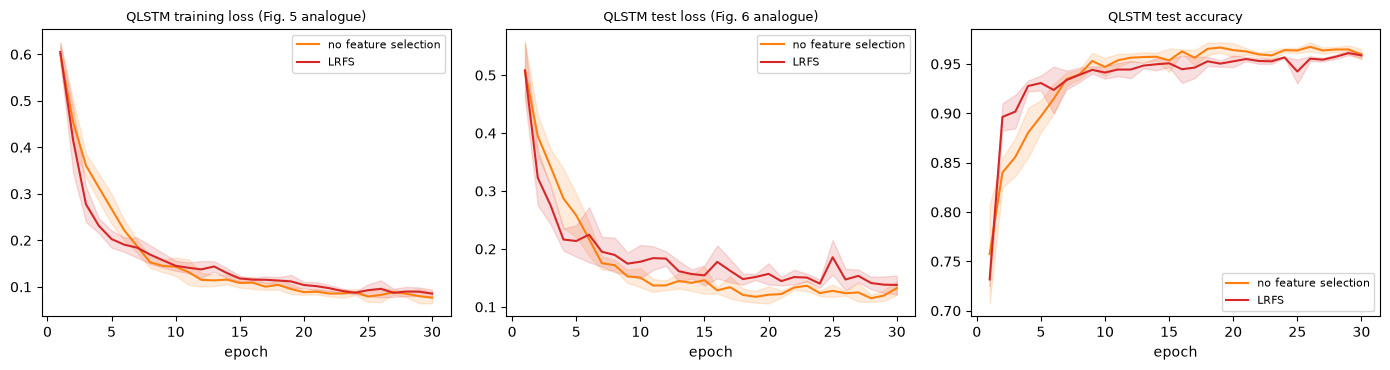

Table 2 analogue: without feature selection
             setting model    accuracy %   precision %      recall %          f1 % train+predict s  runs
no feature selection   ANN 97.29 +- 0.22 97.49 +- 0.10 98.68 +- 0.21 98.08 +- 0.16               2     3
no feature selection   RNN 96.27 +- 0.39 96.84 +- 0.11 97.88 +- 0.59 97.36 +- 0.29               3     3
no feature selection  LSTM 96.86 +- 0.39 97.08 +- 0.23 98.49 +- 0.51 97.78 +- 0.28               3     3
no feature selection QLSTM 95.78 +- 0.06 96.43 +- 1.08 97.64 +- 1.27 97.01 +- 0.07             127     3

Table 3 analogue: with LRFS
setting model    accuracy %   precision %      recall %          f1 % train+predict s  runs
   LRFS   ANN 97.11 +- 0.28 97.47 +- 0.05 98.44 +- 0.42 97.95 +- 0.20               2     3
   LRFS   RNN 96.80 +- 0.18 97.19 +- 0.18 98.29 +- 0.45 97.73 +- 0.13               4     3
   LRFS  LSTM 96.99 +- 0.22 97.49 +- 0.03 98.24 +- 0.34 97.86 +- 0.16               3     3
   LRFS QLSTM 95.69 +- 0.26 96.67 

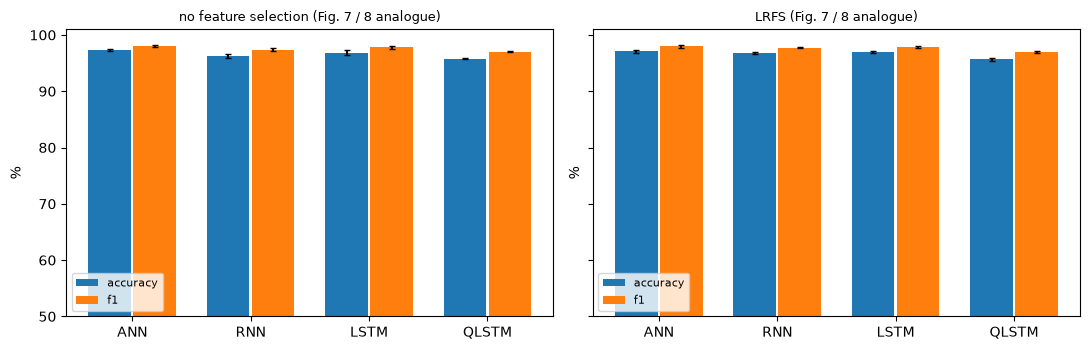

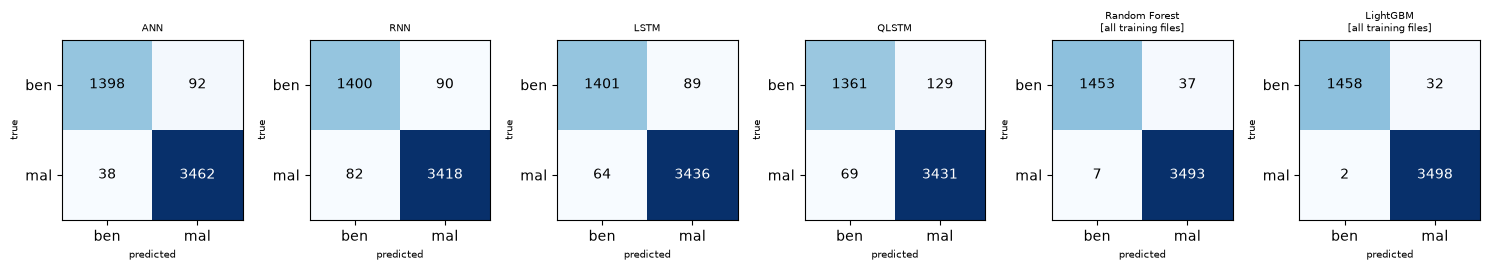

In [16]:
def band(ax, hs, key, label, color, ls="-"):
    A = np.array([h[key] for h in hs]); m, sd = A.mean(0), A.std(0); xs = np.arange(1, A.shape[1] + 1)
    ax.plot(xs, m, label=label, color=color, ls=ls); ax.fill_between(xs, m - sd, m + sd, color=color, alpha=.15)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for setting, c_ in (("no feature selection", "tab:orange"), ("LRFS", "tab:red")):
    hs = HIST[(setting, "QLSTM")]
    band(ax[0], hs, "loss", setting, c_); band(ax[1], hs, "val_loss", setting, c_); band(ax[2], hs, "val_acc", setting, c_)
ax[0].set_title("QLSTM training loss (Fig. 5 analogue)", fontsize=9); ax[1].set_title("QLSTM test loss (Fig. 6 analogue)", fontsize=9); ax[2].set_title("QLSTM test accuracy", fontsize=9)
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

def tab_for(keys):
    rows = []
    for key in keys:
        rs = RESULTS[key]; d = {"setting": key[0], "model": key[1]}
        for m_ in ("accuracy", "precision", "recall", "f1"):
            v = np.array([r[m_] for r in rs]) * 100; d[m_ + " %"] = f"{v.mean():.2f} +- {v.std():.2f}"
        d["train+predict s"] = f"{np.mean([r['seconds'] for r in rs]):.0f}"; d["runs"] = len(rs); rows.append(d)
    return pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)
print("Table 2 analogue: without feature selection"); print(tab_for([("no feature selection", m) for m in MODEL_ORDER]).to_string(index=False))
print("\nTable 3 analogue: with LRFS");              print(tab_for([("LRFS", m) for m in MODEL_ORDER]).to_string(index=False))
print("\nClassical baselines:");                     print(tab_for([k for k in RESULTS if k[0] in ("no feature selection", "LRFS") and k[1] not in MODEL_ORDER]).to_string(index=False))
print("\nTable 4 analogue: feature selection method");  print(tab_for([(f"FS:{f}", "QLSTM") for f in ("Chi-Square", "RFE", "LR", "LRFS")] + [(f"FS:{f}", "Random Forest") for f in ("Chi-Square", "RFE", "LR", "LRFS")]).to_string(index=False))
print("\nTable 5 analogue: number of layers");           print(tab_for([(f"layers:{L_}", "QLSTM") for L_ in (2, 4, 6, 8)]).to_string(index=False))
print("\nTable 6 analogue: folds (Random Forest, LRFS features)"); print(pd.DataFrame(FOLDS).T.assign(acc=lambda d: (d.acc * 100).round(2), acc_sd=lambda d: (d.acc_sd * 100).round(2), f1=lambda d: (d.f1 * 100).round(2), rec=lambda d: (d.rec * 100).round(2)).to_string())

# Figs. 7-8 analogue: bar charts of accuracy and F1 for ANN / RNN / LSTM / QLSTM
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, setting in zip(ax, ("no feature selection", "LRFS")):
    for j, m_ in enumerate(("accuracy", "f1")):
        vals = [100 * np.mean([r[m_] for r in RESULTS[(setting, nm)]]) for nm in MODEL_ORDER]; sds = [100 * np.std([r[m_] for r in RESULTS[(setting, nm)]]) for nm in MODEL_ORDER]
        a.bar(np.arange(4) + 0.38 * j - 0.19, vals, 0.36, yerr=sds, label=m_, capsize=2)
    a.set_xticks(range(4)); a.set_xticklabels(MODEL_ORDER); a.set_title(setting + " (Fig. 7 / 8 analogue)", fontsize=9); a.set_ylim(50, 101); a.legend(fontsize=8); a.set_ylabel("%")
plt.tight_layout(); plt.show()

keys = [("LRFS", m) for m in MODEL_ORDER] + [("LRFS", "Random Forest [all training files]"), ("LRFS", "LightGBM [all training files]")]
fig, ax = plt.subplots(1, len(keys), figsize=(2.5 * len(keys), 2.9))
for a, key in zip(np.atleast_1d(ax), keys):
    cm = CM[key]; a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_xticklabels(["ben", "mal"]); a.set_yticks([0, 1]); a.set_yticklabels(["ben", "mal"])
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")
    a.set_title(key[1].replace(" [", "\n["), fontsize=7); a.set_xlabel("predicted", fontsize=7); a.set_ylabel("true", fontsize=7)
plt.tight_layout(); plt.show()

## 10. Side by side with the paper, claim by claim

Verdict rule (project brief): a metric is **reproduced** when our value lies within 2 percentage points of the paper's, otherwise **exceeded** (ours higher) or **not reached** (ours lower) with the gap; **cannot be checked** when the claim cannot be tested with the information and compute available. "Ours" is the mean over seeds at the last epoch. Ranking claims are checked on the means.

In [17]:
def mean_of(key, m_): return 100 * float(np.mean([r[m_] for r in RESULTS[key]]))
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

T2 = {"ANN": (89.65, 85.00), "RNN": (89.58, 85.00), "LSTM": (83.78, 82.00), "QLSTM": (97.55, 97.00)}      # accuracy, F1 (Table 2)
T3 = {"ANN": (89.71, 85.00), "RNN": (91.32, 90.00), "LSTM": (93.80, 92.00), "QLSTM": (98.85, 98.29)}      # Table 3
rows = []
for tname, T, setting in (("Table 2", T2, "no feature selection"), ("Table 3", T3, "LRFS")):
    for nm in MODEL_ORDER:
        for j, m_ in enumerate(("accuracy", "f1")):
            o = mean_of((setting, nm), m_); rows.append([f"{tname}, {nm}, {m_}", f"{T[nm][j]:.2f}%", f"{o:.2f}%", verdict(o, T[nm][j])])
for m_, pv in (("recall", 98.0),):
    o = mean_of(("LRFS", "QLSTM"), m_); rows.append([f"Table 3, QLSTM, recall (sensitivity = recall by definition)", f"{pv:.2f}%", f"{o:.2f}%", verdict(o, pv)])
# ranking claims
for setting, tname in (("no feature selection", "Table 2"), ("LRFS", "Table 3")):
    acc = {nm: mean_of((setting, nm), "accuracy") for nm in MODEL_ORDER}
    best = max(acc, key=acc.get)
    rows.append([f"{tname}: QLSTM is the best of ANN / RNN / LSTM / QLSTM", "QLSTM best", f"best = {best} ({acc[best]:.2f}%); QLSTM {acc['QLSTM']:.2f}%, LSTM {acc['LSTM']:.2f}%", "reproduced" if best == "QLSTM" else "not reached"])
    rows.append([f"{tname}: QLSTM beats the matched classical LSTM (same recipe)", "yes", f"{acc['QLSTM']:.2f}% vs {acc['LSTM']:.2f}% (gap {acc['QLSTM']-acc['LSTM']:+.2f})", "reproduced" if acc["QLSTM"] > acc["LSTM"] else "not reached"])
gain_q = mean_of(("LRFS", "QLSTM"), "accuracy") - mean_of(("no feature selection", "QLSTM"), "accuracy")
gain_l = mean_of(("LRFS", "LSTM"), "accuracy") - mean_of(("no feature selection", "LSTM"), "accuracy")
rows.append(["Gain of LRFS for the QLSTM, accuracy points (98.85 - 97.55)", "+1.30", f"{gain_q:+.2f}", verdict(gain_q, 1.30) + ("; direction " + ("reproduced" if gain_q > 0 else "not reached"))])
rows.append(["Gain of LRFS for the LSTM, accuracy points (93.80 - 83.78)", "+10.02", f"{gain_l:+.2f}", verdict(gain_l, 10.02) + ("; direction " + ("reproduced" if gain_l > 0 else "not reached"))])
# Table 4
T4 = {"Chi-Square": (90.17, 91.0), "RFE": (90.17, 92.0), "LR": (90.83, 91.0), "LRFS": (98.85, 98.29)}
for fs, (pa, pf) in T4.items():
    o = mean_of((f"FS:{fs}", "QLSTM"), "accuracy"); rows.append([f"Table 4, {fs} + QLSTM, accuracy", f"{pa:.2f}%", f"{o:.2f}%", verdict(o, pa)])
acc4 = {fs: mean_of((f"FS:{fs}", "QLSTM"), "accuracy") for fs in T4}; b4 = max(acc4, key=acc4.get)
rows.append(["Table 4: LRFS is the best selection for the QLSTM", "LRFS best, by 8 points", f"best = {b4}; LRFS {acc4['LRFS']:.2f}% vs next {max(v for k, v in acc4.items() if k != 'LRFS'):.2f}%", "reproduced" if b4 == "LRFS" and acc4['LRFS'] - max(v for k, v in acc4.items() if k != 'LRFS') > 2 else ("not reached (margin below 2 points)" if b4 == "LRFS" else "not reached")])
# Table 5
T5 = {2: 95.08, 4: 96.14, 6: 97.40, 8: 98.85}
for L_, pa in T5.items():
    o = mean_of((f"layers:{L_}", "QLSTM"), "accuracy"); rows.append([f"Table 5, {L_} layers, accuracy", f"{pa:.2f}%", f"{o:.2f}%", verdict(o, pa)])
a5 = [mean_of((f"layers:{L_}", "QLSTM"), "accuracy") for L_ in T5]
rows.append(["Table 5: accuracy rises with the number of layers (8 best)", "2<4<6<8", " < ".join(f"{a:.2f}" for a in a5), "reproduced" if all(np.diff(a5) > 0) else "not reached (not monotone)"])
# Table 6
T6 = {2: 94.10, 3: 96.00, 4: 97.51, 5: 98.93}
for kf, pa in T6.items():
    o = FOLDS[kf]["acc"] * 100; rows.append([f"Table 6, {kf} folds, accuracy (ours: Random Forest, not QLSTM)", f"{pa:.2f}%", f"{o:.2f}%", "cannot be checked for the QLSTM; RF: " + verdict(o, pa)])
a6 = [FOLDS[kf]["acc"] * 100 for kf in T6]
rows.append(["Table 6: accuracy rises with the number of folds (Random Forest)", "2<3<4<5", " < ".join(f"{a:.2f}" for a in a6), "reproduced (for RF)" if all(np.diff(a6) > 0) else "not reached (RF: not monotone)"])
# Table 7 and headline
lgb_acc = mean_of(("LRFS", "LightGBM [all training files]"), "accuracy"); lgb_rec = mean_of(("LRFS", "LightGBM [all training files]"), "recall"); lgb_f1 = mean_of(("LRFS", "LightGBM [all training files]"), "f1")
rows.append(["Table 7, LGBM [24] accuracy (our LightGBM on this data; [24] used other data)", "92.94%", f"{lgb_acc:.2f}%", "not comparable: different dataset and protocol; ours " + verdict(lgb_acc, 92.94)])
rows.append(["Table 7, LGBM [24] F1 (same caveat)", "92.52%", f"{lgb_f1:.2f}%", "not comparable; ours " + verdict(lgb_f1, 92.52)])
for nm in ("PROUD-MAL [17] (acc 98.09, F1 98.33)", "DL-CNN [19] (recall 95, F1 95)", "M-Attn [20] (acc 98, recall 98, F1 97)"):
    rows.append([f"Table 7, {nm}", "from the cited papers", "-", "cannot be checked (other methods and data, not re-run)"])
o = mean_of(("LRFS", "QLSTM"), "accuracy"); rows.append(["Headline: LRFS-QLSTM accuracy 98.85% on the 70/30 split", "98.85%", f"{o:.2f}%", verdict(o, 98.85)])
o = mean_of(("LRFS", "QLSTM"), "f1"); rows.append(["Headline: LRFS-QLSTM F1 99.36% (abstract; best-fold value of Table 6)", "99.36%", f"{o:.2f}%", verdict(o, 99.36)])
rk = max(("LRFS", "Random Forest [all training files]"), ("LRFS", "LightGBM [all training files]"), key=lambda k: mean_of(k, "accuracy"))
rows.append(["Claim: the quantum model is better than strong classical models on this data (our added check)", "implied", f"QLSTM {mean_of(('LRFS','QLSTM'),'accuracy'):.2f}% vs {rk[1]} {mean_of(rk,'accuracy'):.2f}%", "reproduced" if mean_of(("LRFS", "QLSTM"), "accuracy") > mean_of(rk, "accuracy") else "not reached"])
# internal consistency of the paper's tables
rows.append(["Check: sensitivity and recall are the same quantity TP/(TP+FN) (Table 3 QLSTM: 98.60 vs 98.00)", "equal", "differ in the paper", "inconsistent"])
rows.append(["Check: Table 5, 8 layers row (98.85 / 98.6 / 98 / 98) vs Table 3 QLSTM F1 98.29", "same run", "F1 98 vs 98.29", "inconsistent (rounding?)"])
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 100); pd.set_option("display.width", 250)
print(CMP.to_string(index=False))

                                                                                         claim                  paper                                        this notebook                                                              verdict
                                                                        Table 2, ANN, accuracy                 89.65%                                               97.29%                                                      exceeded (+7.6)
                                                                              Table 2, ANN, f1                 85.00%                                               98.08%                                                     exceeded (+13.1)
                                                                        Table 2, RNN, accuracy                 89.58%                                               96.27%                                                      exceeded (+6.7)
                                        

## 11. Reading the paper critically

The headline is that LRFS-QLSTM reaches 98.85 % accuracy (F1 99.36 %) and beats ANN, RNN, LSTM and published detectors. What the paper itself shows, and what this notebook measured (full run: 3 seeds, 1,600 training files, 30 epochs, see the verdict table), supports a more careful reading.

1. **The dataset description does not match the data.** The paper states 19,611 malware and 31,600 benign samples (38.54 % / 61.46 %), 51,211 files in all. The public Kaggle PE dataset with 77 header features has **19,611 files in total** (14,599 malware, 5,012 benign, 74 % malware). The row count and the feature count agree with the paper, the class counts do not; either the text mixes two datasets or the figures were mis-copied. Our class balance is therefore different from the paper's.
2. **A label leak sits in the file.** The `Name` column starts with `VirusShare_` for every malware sample and never for a benign one, so a model that sees it is perfect. We drop it. The paper does not say whether it did. About 15 % of the rows (2,980) are exact duplicates; a Random Forest on the raw file with duplicates scores 99.20 % against 99.06 % after removing them, so here duplicates inflate the number only slightly.
3. **The baselines of Tables 2 and 3 are weak, ours are not.** With the same inputs and the same training recipe, the matched ANN, RNN and LSTM reach 96-97 % accuracy, 3 to 13 points above the paper's 84-94 %. The paper's weak classical numbers (for example an LSTM at 83.78 % without feature selection) come from classical models that were evidently not trained to convergence. That gap is what makes the QLSTM look better in the paper; it disappears once the baselines are trained properly.
4. **The ranking of the paper is not reproduced.** In our runs the QLSTM (95.7-95.8 % accuracy, F1 about 97 %) is 1.1-1.3 points *below* the matched classical LSTM and about 1.4-1.5 points below the ANN, and about 3.5 points below a Random Forest or LightGBM trained on all training rows (99.1-99.3 %). It does land in the paper's range for Table 2 (97.55 %, within 2 points) but not for Table 3 (98.85 %). We trained on a subsample (1,600 files) and for 30 epochs instead of all files and 100 epochs, so the QLSTM may improve with the full budget; the classical networks had the same budget and converged long before.
5. **Feature selection did not help here.** LRFS (47 of 69 features) changes the QLSTM by -0.09 points and the matched LSTM by +0.13 points, against +1.3 and +10.0 in the paper. LASSO with a sensible penalty removes only the redundant columns; the other selectors give the same accuracy within the seed noise (Table 4: RFE 96.6, Chi-square 96.3, LR 95.9, LRFS 95.8 for the QLSTM; the Random Forest gives 98.7-99.2 % for all four). The paper's 8-point margin of LRFS over the other selectors is not reproduced, and the paper does not say which classifier was used in Table 4.
6. **More layers did not help monotonically.** Accuracy with 2, 4, 6, 8 layers was 95.4, 95.8, 95.5, 95.8 % (two seeds each, standard deviation 0.2-0.5), a flat curve inside the noise, not the clean 95.1 -> 98.9 staircase of Table 5. The training time, in contrast, doubles from 4 to 8 layers on a simulator.
7. **The cross-fold table measures training-set size, not the model.** Going from 2 to 5 folds raises the training share from 50 % to 80 %, so any model improves (Random Forest here: 98.83 -> 99.12 %). The abstract's F1 of 99.36 % is the best-fold value of Table 6, not the 70/30 result of Table 3 (98.29 %).
8. **The tables are internally inconsistent.** "Sensitivity" and "recall" are the same quantity TP/(TP+FN), yet every table lists different values for them; Table 3 gives F1 98.29 % while Table 5's 8-layer row (the same configuration) gives 98 %; several F1 values do not follow from the other columns.
9. **The "sequence" is artificial.** PE-header fields have no temporal order, so the LSTM memory has nothing to remember; the order of the fields in the file is arbitrary. Exercise 1 asks you to test that. Nothing in the paper shows a benefit from quantum circuits that cannot be obtained from a classical network of similar size: the QLSTM has 921 trainable parameters (576 circuit angles) against 585 for the matched LSTM.
10. **Table 7 compares unlike things.** The numbers of PROUD-MAL, DL-CNN, M-Attn and LGBM are copied from papers that used other data and protocols (LGBM [24] studies adversarial attacks on EMBER); the table is not a controlled comparison. A LightGBM run on this data reaches 99.3 %.

## 12. Exercises

1. **Sequence layout.** The notebook cuts the selected features into groups of `G_STEP` in column order. Shuffle the column order (or sort the features by LASSO coefficient) and retrain the QLSTM. Does the accuracy change? What does that say about the claim that the model exploits "temporal dependencies"?
2. **Qubits and depth.** Change `N_QUBITS` to 3 and 6 and `Q_DEPTH` to 1. How does the number of trainable parameters, the training time and the test accuracy change? Is 8 layers really needed?
3. **Balanced classes.** The file is about 70 % malware. Re-run with `class_weight`-style balancing (for example `pos_weight` in the loss, or balanced sub-sampling of `N_TRAIN` files) and compare recall on the benign class.
4. **Hold-out by family.** All malware here comes from VirusShare. Hold out the 'sbs', 'kd' and other benign name prefixes (or split by `TimeDateStamp`) and test how the models behave on files that differ from the training files.
5. **Budget.** Set `FAST_MODE = False` and raise `EPOCHS` towards the paper's 100. Does the QLSTM keep improving or does the test loss stop falling after about 10 epochs, as the paper says?